# Live demo — SAE features in Boltz-Prot-1 designs

**APMA 4903 · Vignesh Karthik, Parsa Talaie, Junsung Lee**

| block | what it does |
|---|---|
| **1** | design 100 binders against Reg3A epitope **112–130** |
| **2** | embed each design with **ESM-C 300M**, binder co-attended with target |
| **3** | run every residue through the trained **SAE** |
| **4** | report FVE — all designs, and ipTM > 0.7 designs only |
| **5** | count designs where **feature 14364** fires **at the interface** (≤ 5 Å) |
| **6** | histograms + an interactive **PyMOL** session on the top design |

Run top to bottom.

## 0 — setup

In [2]:
import json, os, subprocess, sys, tarfile, time, warnings
from pathlib import Path

import httpx
import numpy as np
import pandas as pd
import torch
import matplotlib as mpl
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

def find_root(marker):
    here = Path.cwd().resolve()
    for d in [here, *here.parents]:
        if (d / marker).exists():
            return d
    raise SystemExit(f"could not find {marker} from {here}")

REPO      = find_root("config/reg3a_target.fasta")
DATA_ROOT = find_root("03_train/checkpoints/reg3a_layer23_paired/best.pt")
CKPT      = DATA_ROOT / "03_train/checkpoints/reg3a_layer23_paired/best.pt"
OUT       = REPO / "results/live_demo"
STRUCTS   = OUT / "structures"
OUT.mkdir(parents=True, exist_ok=True); STRUCTS.mkdir(exist_ok=True)
sys.path.insert(0, str(REPO / "03_train"))
sys.path.insert(0, str(REPO / "05_interpret"))

EPITOPE      = list(range(112, 131))   # 1-indexed on the 138-residue target
N_DESIGNS    = 100
BINDER_SPEC  = "55..75"
FEATURE      = 14364                   # the interface feature from block 5 of the talk
CONTACT_CUT  = 5.0                     # Angstrom, heavy-atom
IPTM_GATE    = 0.7
LAYER        = 23

TARGET = "".join(l.strip() for l in (REPO/"config/reg3a_target.fasta").read_text().splitlines()
                 if l and not l.startswith(">")).upper()
print(f"target {len(TARGET)} aa · epitope {EPITOPE[0]}-{EPITOPE[-1]} · "
      f"feature {FEATURE} · out {OUT}")

target 138 aa · epitope 112-130 · feature 14364 · out /Users/vigneshkarthik/Documents/CLASSES/Mol_bio_APMA_Seminar/results/live_demo


In [3]:
# plot style — validated palette slots 1-2, hairline chrome
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8980", "#e6e6e2"
BLUE, ORANGE = "#2a78d6", "#eb6834"
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 13, "axes.labelsize": 13,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": GRID, "axes.linewidth": 0.8, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.grid": True, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "figure.autolayout": False,
})

def finish(fig, title, sub=None):
    fig.tight_layout(rect=[0, 0, 1, 0.84 if sub else 0.90])
    fig.text(0.012, 0.975, title, ha="left", va="top", fontsize=15, color=INK)
    if sub:
        fig.text(0.012, 0.898, sub, ha="left", va="top", fontsize=11.5, color=MUTED)

## 1 — design 100 binders against epitope 112–130

`SUBMIT = True` sends a new job. To analyse a job you already ran, put its id
in `RUN_ID` and leave `SUBMIT = False`.

A **test** key (`sk_bc_*_test_`) returns synthetic sequences and stub
structures — fine for checking the plumbing, useless for the science. The
banner says which you are on.

In [6]:
SUBMIT = True
RUN_ID = None          # e.g. "prot_des_..." to reuse an existing run
POLL_TIMEOUT_MIN = 30

BASE = os.environ.get("BOLTZ_BASE_URL", "https://api.boltz.bio")
key  = "insert_key"
LIVE = "_test_" not in key
print("=" * 60)
print("  LIVE MODE — real designs, real charges" if LIVE
      else "  TEST MODE — synthetic sequences and stub structures")
print("=" * 60)

api = httpx.Client(base_url=BASE, headers={"x-api-key": key}, timeout=120.0)

body = {
    "num_proteins": N_DESIGNS,
    "target": {"type": "no_template",
               "entities": [{"type": "protein", "chain_ids": ["A"], "value": TARGET}],
               "epitope_residues": {"A": [r - 1 for r in EPITOPE]}},   # API is 0-indexed
    "binder_specification": {"type": "no_template", "modality": "custom_protein",
                             "entities": [{"type": "designed_protein",
                                           "chain_ids": ["B"], "value": BINDER_SPEC}]},
}

cost = api.post("/compute/v1/protein/design/estimate-cost", json=body).json()
print(f"\n{N_DESIGNS} designs · epitope {EPITOPE[0]}-{EPITOPE[-1]} · "
      f"binder {BINDER_SPEC} · estimated ${cost['estimated_cost_usd']}")

if SUBMIT:
    r = api.post("/compute/v1/protein/design", json=body); r.raise_for_status()
    RUN_ID = r.json()["id"]
    print(f"submitted: {RUN_ID}")

assert RUN_ID, "set SUBMIT = True, or supply RUN_ID"

t0 = time.time()
while True:
    run = api.get(f"/compute/v1/protein/design/{RUN_ID}").json()
    p = run.get("progress") or {}
    done, total = p.get("num_proteins_generated", 0), p.get("total_proteins_to_generate", N_DESIGNS)
    print(f"\r  {run['status']:<10} {done}/{total}  ({time.time()-t0:.0f}s)", end="", flush=True)
    if run["status"] in ("succeeded", "failed", "stopped"):
        break
    if (time.time() - t0) / 60 > POLL_TIMEOUT_MIN:
        raise SystemExit(f"\nstill {run['status']} after {POLL_TIMEOUT_MIN} min")
    time.sleep(10)
print(f"\n{run['status']}")

  LIVE MODE — real designs, real charges

100 designs · epitope 112-130 · binder 55..75 · estimated $2.5000
submitted: prot_des_FOmTkVU7JsPyqk1ipU8A
  succeeded  100/100  (292s)
succeeded


In [8]:
# pull every design: sequences, metrics, and its predicted complex
rows, cursor = [], None
while True:
    params = {"limit": 100}
    if cursor:
        params["after_id"] = cursor
    page = api.get(f"/compute/v1/protein/design/{RUN_ID}/results", params=params).json()
    for rec in page["data"]:
        chains = {c["chain_ids"][0]: c["value"] for c in rec["entities"]}
        rows.append({"id": rec["id"], "binder": chains.get("B", ""),
                     **rec["metrics"],
                     "structure_url": rec["artifacts"]["structure"]["url"]})
    if not page.get("has_more"):
        break
    cursor = page["last_id"]

designs = pd.DataFrame(rows)
print(f"{len(designs)} designs returned")

# make the directory here, not only in the setup cell -- it may have been
# cleaned up since, and this cell has to stand on its own.
STRUCTS.mkdir(parents=True, exist_ok=True)

for n, r in enumerate(designs.itertuples(), 1):     # download the complexes
    path = STRUCTS / f"{r.id}.cif"
    if not path.exists():
        resp = httpx.get(r.structure_url, timeout=120, follow_redirects=True)
        # presigned URLs expire (~30 min). Fail loudly rather than writing an
        # S3 error page to disk as a .cif and breaking block 5 confusingly.
        resp.raise_for_status()
        path.write_bytes(resp.content)
    if n % 25 == 0 or n == len(designs):
        print(f"\r  downloaded {n}/{len(designs)}", end="", flush=True)

designs["cif"] = [str(STRUCTS / f"{i}.cif") for i in designs.id]
print(f"\nstructures in {STRUCTS}")
display(designs[["id", "iptm", "binding_confidence", "structure_confidence"]].head())

100 designs returned
  downloaded 100/100
structures in /Users/vigneshkarthik/Documents/CLASSES/Mol_bio_APMA_Seminar/results/live_demo/structures


,id,iptm,binding_confidence,structure_confidence
0,pres_y6r6qHzJSMo9k41xJA0J,0.776189,1.656277e-05,0.542769
1,pres_LnZDbj0ETiT6bx98CIRR,0.327360,4.290528e-07,0.150189
2,pres_Yfzf3xhVSygOJuvED5kg,0.748815,8.667530e-07,0.500880
3,pres_JbLFi5kuJoDpwR2XTQyX,0.637505,2.926781e-07,0.331611
4,pres_HA2JukXx7lWk5xxaZKic,0.466575,5.163661e-07,0.250988


## 2 — embed with ESM-C 300M

Binder and target are concatenated across ESM-C's native chain-break token, so
attention sees both; we keep only the binder's residue vectors.

In [10]:
from transformers.models.esmc.modeling_esmc import EsmcForMaskedLM
from transformers.models.esmc.tokenization_esmc import EsmcTokenizer

device = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda" if torch.cuda.is_available() else "cpu")
tok = EsmcTokenizer.from_pretrained("biohub/ESMC-300M")
esm = EsmcForMaskedLM.from_pretrained("biohub/ESMC-300M").to(device).eval()

@torch.no_grad()
def embed(seqs, batch=16):
    out = []
    for i in range(0, len(seqs), batch):
        chunk = seqs[i:i + batch]
        enc = tok([s + "|" + TARGET for s in chunk], return_tensors="pt", padding=True)
        hid = esm(input_ids=enc["input_ids"].to(device),
                  attention_mask=enc["attention_mask"].to(device),
                  output_hidden_states=True).hidden_states[LAYER].float()
        out += [hid[j, 1:1 + len(s)].cpu().numpy() for j, s in enumerate(chunk)]
    return out

acts = embed(designs.binder.tolist())
print(f"embedded {len(acts)} designs · {sum(a.shape[0] for a in acts):,} residues "
      f"· layer {LAYER} · {acts[0].shape[1]}-dim")

W1016 14:36:09.475000 67742 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|█████████████████████| 398/398 [00:00<00:00, 6369.73it/s]


embedded 100 designs · 6,357 residues · layer 23 · 960-dim


## 3 — run every residue through the SAE

$$z = \mathrm{TopK}_{64}(W_{\mathrm{enc}}^\top x_p + b_{\mathrm{enc}}),
\qquad \hat{x} = W_{\mathrm{dec}}^\top z + b_{\mathrm{dec}},
\qquad x_p = (x - \mu)\,s$$

$\mu$ and $s$ are frozen in the checkpoint, so these numbers are comparable to
the training figures.

In [13]:
# --- Python 3.13 -> 3.10 unpickling shim -----------------------------------
# best.pt was saved by the project venv (Python 3.13), where pathlib is a
# PACKAGE, so the Path objects in ck["args"] pickled as
# pathlib._local.PosixPath. This Jupyter runs 3.10, where pathlib is a plain
# module and that name does not exist -> ModuleNotFoundError.
# Point the old name at the real classes before unpickling.
import sys, types, pathlib

if sys.version_info < (3, 13) and "pathlib._local" not in sys.modules:
    _shim = types.ModuleType("pathlib._local")
    for _n in ("Path", "PosixPath", "WindowsPath",
               "PurePath", "PurePosixPath", "PureWindowsPath"):
        setattr(_shim, _n, getattr(pathlib, _n))
    sys.modules["pathlib._local"] = _shim
# ---------------------------------------------------------------------------

from interface_activations import load_sae, classify_design
sae, MEAN, SCALE, D_HIDDEN = load_sae(CKPT, device)
FVE_TRAIN = float(torch.load(CKPT, map_location="cpu", weights_only=False)["val_fve"])

@torch.no_grad()
def run_sae(a):
    """-> sparse codes, squared error, squared input norm (for FVE)."""
    x  = torch.from_numpy(a).to(device)
    xp = (x.float() - MEAN) * SCALE
    recon, _, _, z = sae(xp)
    return (z.cpu().numpy(),
            (xp - recon).pow(2).sum().item(),
            xp.pow(2).sum().item())

codes, se, sx = [], [], []
for a in acts:
    z, e, s = run_sae(a); codes.append(z); se.append(e); sx.append(s)
designs["se"], designs["sx"], designs["n_res"] = se, sx, [a.shape[0] for a in acts]

print(f"dictionary {D_HIDDEN} features · L0 = "
      f"{np.mean([(z != 0).sum(-1).mean() for z in codes]):.1f} per residue")

dictionary 16384 features · L0 = 64.0 per residue


## 4 — FVE, all designs and high-quality designs

$\mathrm{FVE} = 1 - \sum\lVert x_p-\hat{x}\rVert^2 / \sum\lVert x_p\rVert^2$,
pooled over residues exactly as in training. Reported twice: over everything,
and over residues belonging to designs with ipTM > 0.7 — in case there are too
few good designs in a run of 100 for the first number to mean much.

In [14]:
def fve(df):
    return 1.0 - df.se.sum() / max(df.sx.sum(), 1e-12)

# per-design FVE first, so the high-quality slice carries it too
designs["fve"] = 1.0 - designs.se / designs.sx.clip(lower=1e-12)
hq = designs[designs.iptm > IPTM_GATE]
FVE_ALL, FVE_HQ = fve(designs), (fve(hq) if len(hq) else float("nan"))

print(f"all designs        n={len(designs):>3}  "
      f"{designs.n_res.sum():>6,} residues   FVE = {FVE_ALL:.4f}")
print(f"ipTM > {IPTM_GATE}         n={len(hq):>3}  "
      f"{hq.n_res.sum():>6,} residues   FVE = {FVE_HQ:.4f}")
print(f"held-out at training                       FVE = {FVE_TRAIN:.4f}")
if len(hq) < 10:
    print(f"\nNOTE: only {len(hq)} designs pass the gate — the high-quality "
          f"figure rests on very little.")

all designs        n=100   6,357 residues   FVE = 0.9455
ipTM > 0.7         n= 45   2,833 residues   FVE = 0.9545
held-out at training                       FVE = 0.9687


## 5 — does feature 14364 fire *at the interface*?

For each design, compute every binder residue's minimum heavy-atom distance to
any target atom. A residue is at the interface if that distance is ≤ 5 Å. Then
ask, per design: does feature 14364 fire on any such residue?

Firing anywhere else does not count.

In [15]:
hits, n_iface, skipped = [], [], []
for r, z in zip(designs.itertuples(), codes):
    geo = classify_design(r.id, r.cif, r.binder, "A", "B", CONTACT_CUT, 10.0)
    if geo.get("error"):
        skipped.append((r.id, geo["error"])); hits.append(False); n_iface.append(0); continue
    contact = np.array([t == "contact" for t in geo["tiers"]])
    fires   = z[:, FEATURE] > 0
    hits.append(bool((fires & contact).any()))
    n_iface.append(int((fires & contact).sum()))

designs["fires_at_interface"] = hits
designs["n_interface_firings"] = n_iface

n_ok = len(designs) - len(skipped)
print(f"feature {FEATURE} fires at the interface in "
      f"{designs.fires_at_interface.sum()} of {n_ok} designs "
      f"({100*designs.fires_at_interface.sum()/max(n_ok,1):.1f}%)")
print(f"interface residues: "
      f"{designs.n_interface_firings.sum()} firings total")
if skipped:
    print(f"\n{len(skipped)} skipped (structure/sequence mismatch): {skipped[:2]}")

feature 14364 fires at the interface in 5 of 100 designs (5.0%)
interface residues: 18 firings total


## 6 — figures, and PyMOL on the top design

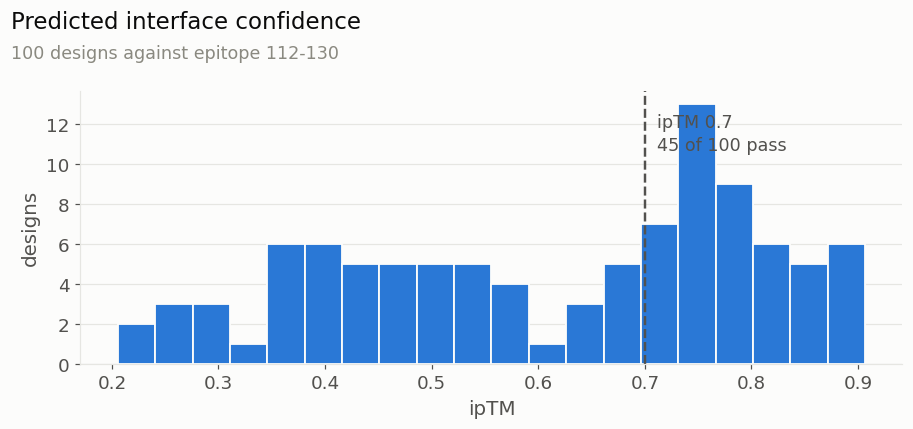

In [16]:
# ---- ipTM distribution ----------------------------------------------------
fig, ax = plt.subplots(figsize=(8.4, 4.0))
ax.hist(designs.iptm, bins=20, color=BLUE, edgecolor=SURFACE, linewidth=1.2)
ax.axvline(IPTM_GATE, color=INK_2, lw=1.6, ls="--")
ax.annotate(f"ipTM {IPTM_GATE}\n{len(hq)} of {len(designs)} pass",
            xy=(IPTM_GATE, ax.get_ylim()[1]*0.92), xytext=(8, 0),
            textcoords="offset points", ha="left", va="top",
            fontsize=11.5, color=INK_2, linespacing=1.4)
ax.set_xlabel("ipTM"); ax.set_ylabel("designs"); ax.grid(axis="x", visible=False)
finish(fig, "Predicted interface confidence",
       f"{len(designs)} designs against epitope {EPITOPE[0]}-{EPITOPE[-1]}")
plt.show()

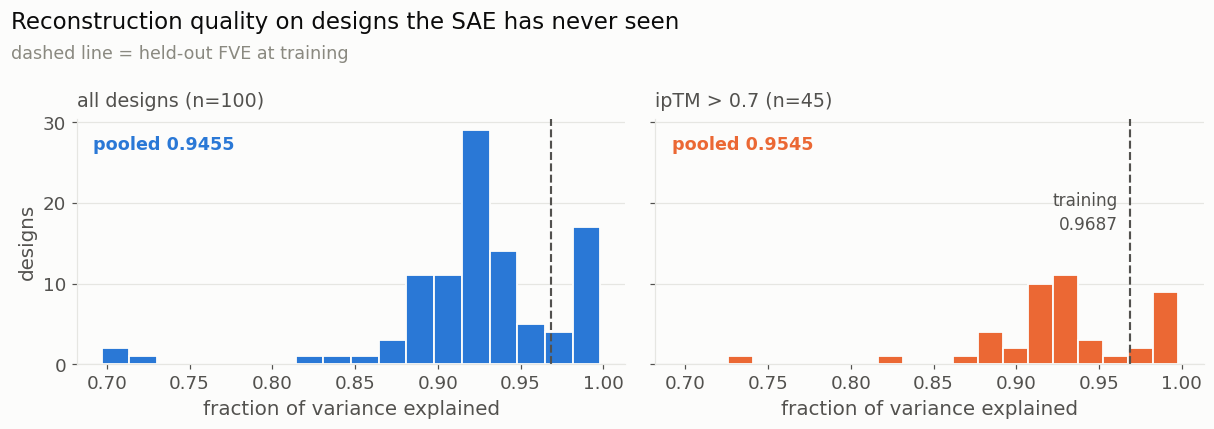

In [17]:
# ---- FVE: all designs, and high-quality only ------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.0), sharex=True, sharey=True)
for ax, (sub, col, lab, f) in zip(axes, [
        (designs, BLUE,   f"all designs (n={len(designs)})",     FVE_ALL),
        (hq,      ORANGE, f"ipTM > {IPTM_GATE} (n={len(hq)})",   FVE_HQ)]):
    if len(sub):
        ax.hist(sub.fve, bins=18, color=col, edgecolor=SURFACE, linewidth=1.2)
    ax.axvline(FVE_TRAIN, color=INK_2, lw=1.4, ls="--")
    ax.set_title(lab, loc="left", fontsize=12.5, color=INK_2, pad=8)
    ax.set_xlabel("fraction of variance explained")
    ax.grid(axis="x", visible=False)
    if np.isfinite(f):
        ax.annotate(f"pooled {f:.4f}", xy=(0.03, 0.93), xycoords="axes fraction",
                    fontsize=11.5, color=col, fontweight="semibold", va="top")
axes[0].set_ylabel("designs")
axes[1].annotate(f"training\n{FVE_TRAIN:.4f}", xy=(FVE_TRAIN, axes[1].get_ylim()[1]*0.55),
                 xytext=(-8, 0), textcoords="offset points", ha="right",
                 fontsize=11, color=INK_2, linespacing=1.4)
finish(fig, "Reconstruction quality on designs the SAE has never seen",
       "dashed line = held-out FVE at training")
plt.show()

In [18]:
# ---- PyMOL on the top design by Boltz-Prot-1's own score ------------------
top = designs.loc[designs.binding_confidence.idxmax()]
print(f"top design: {top.id}")
print(f"  binding_confidence {top.binding_confidence:.4f}   ipTM {top.iptm:.4f}")
print(f"  fires feature {FEATURE} at interface: {top.fires_at_interface}")

pml = OUT / "top_design.pml"
pml.write_text(f"""
load {top.cif}, complex
hide everything
bg_color white
show cartoon
color grey80, chain A
color marine, chain B
select epitope, chain A and resi {EPITOPE[0]}-{EPITOPE[-1]}
color orange, epitope
show sticks, epitope and not name N+C+O
select iface, byres (chain B within {CONTACT_CUT} of chain A)
show sticks, iface and not name N+C+O
color tv_blue, iface
set cartoon_transparency, 0.15, chain A
orient epitope or iface
set ray_opaque_background, 0
deselect
print "chain A = Reg3A (orange = epitope {EPITOPE[0]}-{EPITOPE[-1]})"
print "chain B = binder {top.id} (blue sticks = interface residues)"
""")

subprocess.Popen(["pymol", str(pml)])      # non-blocking; the GUI opens alongside
print(f"\nPyMOL launching with {pml.name}")

top design: pres_isl2l4Q5u8XbPb77QkfQ
  binding_confidence 0.2306   ipTM 0.8460
  fires feature 14364 at interface: False

PyMOL launching with top_design.pml
 PyMOL(TM) Molecular Graphics System, Version 3.1.0.
 Copyright (c) Schrodinger, LLC.
 All Rights Reserved.
 
    Created by Warren L. DeLano, Ph.D. 
 
    PyMOL is user-supported open-source software.  Although some versions
    are freely available, PyMOL is not in the public domain.
 
    If PyMOL is helpful in your work or study, then please volunteer 
    support for our ongoing efforts to create open and affordable scientific
    software by purchasing a PyMOL Maintenance and/or Support subscription.

    More information can be found at "http://www.pymol.org".
 
    Enter "help" for a list of commands.
    Enter "help <command-name>" for information on a specific command.

 Hit ESC anytime to toggle between text and graphics.

 Detected OpenGL version 2.1. Shaders available.
 Tessellation shaders not available
 Detected GL